# Análisis estadístico de los factores asociados a la pérdida de clientes
**Asignatura:** Diseño Estadístico para Datos Estructurados y no Estructurados  
**Universidad:** Universidad de Cundinamarca  
**Estudiante:** Gabriela Suesca Castillo  
**Docente:** PAUL ALEXANDER DIAZ MONTAÑA  

## Objetivo
Describir la pérdida de clientes (*churn*) en el conjunto de datos de ejemplo IBM Telco Customer Churn y explorar su asociación con el contrato, el método de pago, la antigüedad y los cargos mensuales.

**Importante:** los resultados muestran asociaciones, no demuestran causalidad. Es un conjunto de datos de ejemplo, no información de clientes reales de tu empresa.


## 1. Librerías

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency, mannwhitneyu, levene
from IPython.display import display

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
print("Librerías cargadas correctamente.")

Librerías cargadas correctamente.


## 2. Descargar y cargar los datos

In [2]:
URL_DATOS = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(URL_DATOS)

print(f"Filas: {df.shape[0]:,} | Columnas: {df.shape[1]}")
display(df.head())

Filas: 7,043 | Columnas: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 3. Revisar y preparar los datos

In [3]:
print("Tipos de datos:")
display(df.dtypes.to_frame("Tipo"))

print("Valores faltantes por columna:")
display(df.isna().sum().to_frame("Faltantes"))
print("Filas duplicadas:", df.duplicated().sum())
print("IDs duplicados:", df["customerID"].duplicated().sum())

# Convertir TotalCharges a número. Algunos registros vienen vacíos.
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("TotalCharges vacíos después de convertir:", df["TotalCharges"].isna().sum())

# En este conjunto, los valores vacíos corresponden a registros sin cargos acumulados registrados.
df["TotalCharges"] = df["TotalCharges"].fillna(0)
df["Churn_binario"] = df["Churn"].map({"No": 0, "Yes": 1})

print("Dimensiones finales:", df.shape)
print("Faltantes restantes:", int(df.isna().sum().sum()))
display(df[["tenure", "MonthlyCharges", "TotalCharges"]].describe().round(2))

Tipos de datos:


,Tipo
customerID,object
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object


Valores faltantes por columna:


,Faltantes
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


Filas duplicadas: 0
IDs duplicados: 0
TotalCharges vacíos después de convertir: 11
Dimensiones finales: (7043, 22)
Faltantes restantes: 0


,tenure,MonthlyCharges,TotalCharges
count,7043.00,7043.00,7043.00
mean,32.37,64.76,2279.73
std,24.56,30.09,2266.79
min,0.00,18.25,0.00
25%,9.00,35.50,398.55
50%,29.00,70.35,1394.55
75%,55.00,89.85,3786.60
max,72.00,118.75,8684.80


## 4. Resumen del abandono

,Clientes,Porcentaje
Estado,,
No,5174,73.46
Yes,1869,26.54


Tasa general de abandono: 26.54%


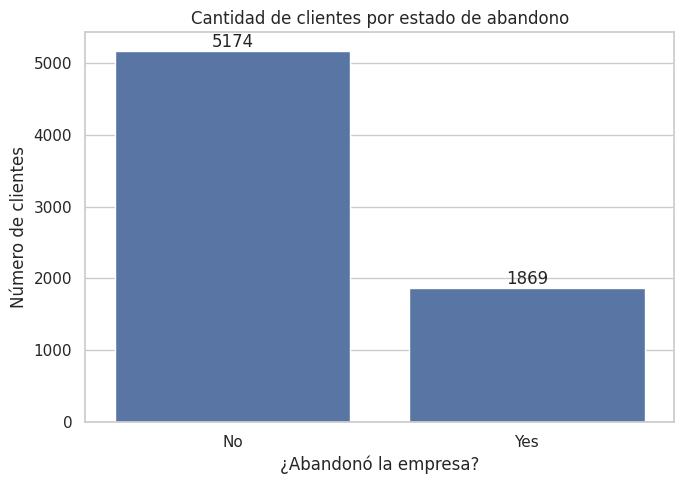

In [4]:
resumen_churn = df["Churn"].value_counts().rename_axis("Estado").to_frame("Clientes")
resumen_churn["Porcentaje"] = (resumen_churn["Clientes"] / len(df) * 100).round(2)
display(resumen_churn)
tasa_abandono = df["Churn_binario"].mean() * 100
print(f"Tasa general de abandono: {tasa_abandono:.2f}%")

plt.figure(figsize=(7,5))
ax = sns.countplot(data=df, x="Churn", order=["No", "Yes"])
ax.set(title="Cantidad de clientes por estado de abandono",
       xlabel="¿Abandonó la empresa?", ylabel="Número de clientes")
for cont in ax.containers:
    ax.bar_label(cont)
plt.tight_layout()
plt.show()

## 5. Visualizaciones por segmento

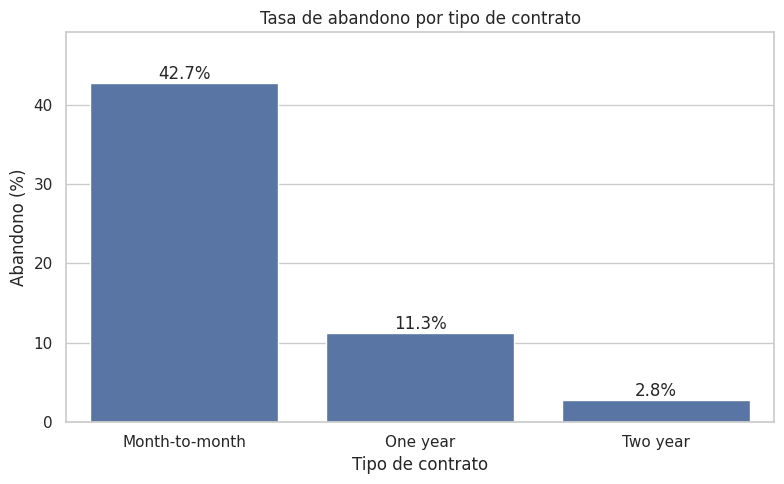

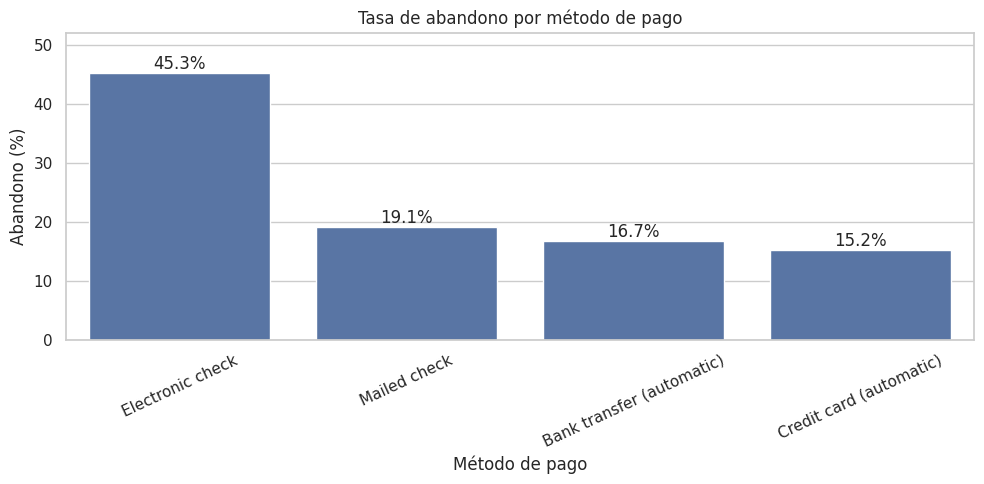

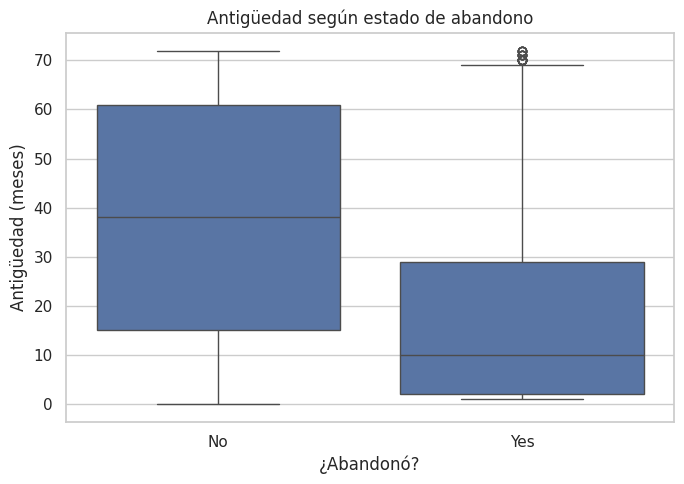

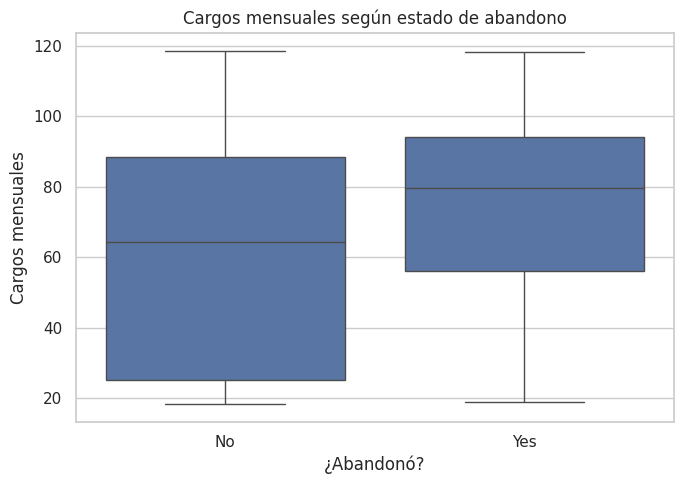

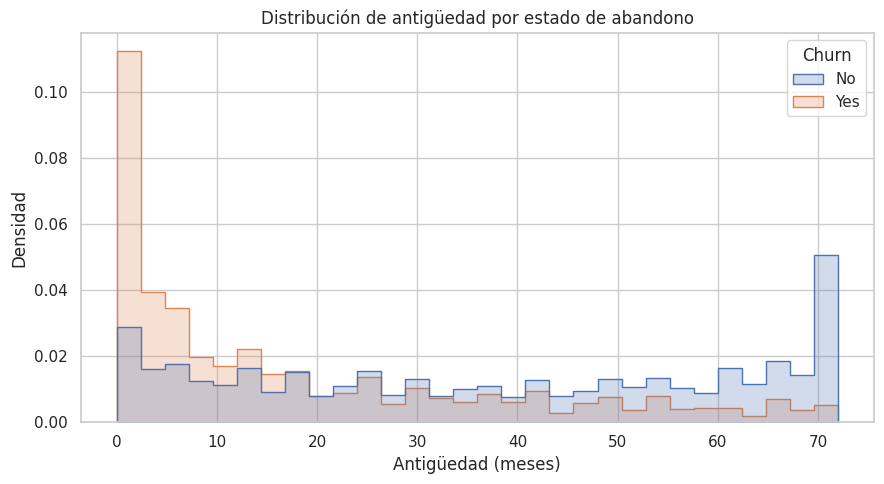

In [5]:
# Tasa de abandono por tipo de contrato
tasa_contrato = df.groupby("Contract")["Churn_binario"].mean().mul(100).sort_values(ascending=False)
plt.figure(figsize=(8,5))
ax = sns.barplot(x=tasa_contrato.index, y=tasa_contrato.values)
ax.set(title="Tasa de abandono por tipo de contrato", xlabel="Tipo de contrato", ylabel="Abandono (%)")
ax.set_ylim(0, max(tasa_contrato.values)*1.15)
for cont in ax.containers: ax.bar_label(cont, fmt="%.1f%%")
plt.tight_layout(); plt.show()

# Tasa de abandono por método de pago
tasa_pago = df.groupby("PaymentMethod")["Churn_binario"].mean().mul(100).sort_values(ascending=False)
plt.figure(figsize=(10,5))
ax = sns.barplot(x=tasa_pago.index, y=tasa_pago.values)
ax.set(title="Tasa de abandono por método de pago", xlabel="Método de pago", ylabel="Abandono (%)")
ax.tick_params(axis="x", rotation=25)
ax.set_ylim(0, max(tasa_pago.values)*1.15)
for cont in ax.containers: ax.bar_label(cont, fmt="%.1f%%")
plt.tight_layout(); plt.show()

# Antigüedad y cargos mensuales comparados por abandono
plt.figure(figsize=(7,5))
sns.boxplot(data=df, x="Churn", y="tenure", order=["No","Yes"])
plt.title("Antigüedad según estado de abandono"); plt.xlabel("¿Abandonó?"); plt.ylabel("Antigüedad (meses)")
plt.tight_layout(); plt.show()

plt.figure(figsize=(7,5))
sns.boxplot(data=df, x="Churn", y="MonthlyCharges", order=["No","Yes"])
plt.title("Cargos mensuales según estado de abandono"); plt.xlabel("¿Abandonó?"); plt.ylabel("Cargos mensuales")
plt.tight_layout(); plt.show()

# Histograma de antigüedad por grupo
plt.figure(figsize=(9,5))
sns.histplot(data=df, x="tenure", hue="Churn", bins=30, element="step", stat="density", common_norm=False)
plt.title("Distribución de antigüedad por estado de abandono")
plt.xlabel("Antigüedad (meses)"); plt.ylabel("Densidad")
plt.tight_layout(); plt.show()

## 6. Tablas comparativas

In [6]:
print("Resumen de variables numéricas según abandono:")
display(df.groupby("Churn")[["tenure","MonthlyCharges","TotalCharges"]]
        .agg(["count","mean","median","std"]).round(2))

print("Contrato y abandono:")
tabla_contrato = pd.crosstab(df["Contract"], df["Churn"])
tabla_contrato["Total"] = tabla_contrato.sum(axis=1)
tabla_contrato["Abandono (%)"] = (tabla_contrato["Yes"] / tabla_contrato["Total"] * 100).round(2)
display(tabla_contrato.sort_values("Abandono (%)", ascending=False))

print("Método de pago y abandono:")
tabla_pago = pd.crosstab(df["PaymentMethod"], df["Churn"])
tabla_pago["Total"] = tabla_pago.sum(axis=1)
tabla_pago["Abandono (%)"] = (tabla_pago["Yes"] / tabla_pago["Total"] * 100).round(2)
display(tabla_pago.sort_values("Abandono (%)", ascending=False))

Resumen de variables numéricas según abandono:


tenure                      MonthlyCharges                       \
       count   mean median    std          count   mean median    std   
Churn                                                                   
No      5174  37.57   38.0  24.11           5174  61.27  64.43  31.09   
Yes     1869  17.98   10.0  19.53           1869  74.44  79.65  24.67   

      TotalCharges                             
             count     mean   median      std  
Churn                                          
No            5174  2549.91  1679.52  2329.95  
Yes           1869  1531.80   703.55  1890.82

Contrato y abandono:


Churn,No,Yes,Total,Abandono (%)
Contract,,,,
Month-to-month,2220,1655,3875,42.71
One year,1307,166,1473,11.27
Two year,1647,48,1695,2.83


Método de pago y abandono:


Churn,No,Yes,Total,Abandono (%)
PaymentMethod,,,,
Electronic check,1294,1071,2365,45.29
Mailed check,1304,308,1612,19.11
Bank transfer (automatic),1286,258,1544,16.71
Credit card (automatic),1290,232,1522,15.24


## 7. Pruebas estadísticas
Se utilizará un nivel de significancia de 0,05. Un valor p menor que 0,05 aporta evidencia estadística de asociación o diferencia. La interpretación debe considerar el contexto y no implica causalidad.

### 7.1. Chi-cuadrado: tipo de contrato y abandono

In [7]:
tabla = pd.crosstab(df["Contract"], df["Churn"])
chi2_contrato, p_contrato, gl_contrato, esperados = chi2_contingency(tabla)
n = tabla.to_numpy().sum()
v_cramer_contrato = np.sqrt(chi2_contrato / (n * min(tabla.shape[0]-1, tabla.shape[1]-1)))
display(tabla)
print(f"Chi-cuadrado={chi2_contrato:.4f}; grados de libertad={gl_contrato}; p={p_contrato:.6g}; V de Cramér={v_cramer_contrato:.4f}")
print("Interpretación:", "hay asociación estadísticamente significativa" if p_contrato < 0.05 else "no hay evidencia suficiente de asociación")

Churn,No,Yes
Contract,,
Month-to-month,2220,1655
One year,1307,166
Two year,1647,48


Chi-cuadrado=1184.5966; grados de libertad=2; p=5.86304e-258; V de Cramér=0.4101
Interpretación: hay asociación estadísticamente significativa


### 7.2. Chi-cuadrado: método de pago y abandono

In [8]:
tabla_pago_chi = pd.crosstab(df["PaymentMethod"], df["Churn"])
chi2_pago, p_pago, gl_pago, esperados_pago = chi2_contingency(tabla_pago_chi)
v_cramer_pago = np.sqrt(chi2_pago / (tabla_pago_chi.to_numpy().sum() * min(tabla_pago_chi.shape[0]-1, tabla_pago_chi.shape[1]-1)))
display(tabla_pago_chi)
print(f"Chi-cuadrado={chi2_pago:.4f}; grados de libertad={gl_pago}; p={p_pago:.6g}; V de Cramér={v_cramer_pago:.4f}")
print("Interpretación:", "hay asociación estadísticamente significativa" if p_pago < 0.05 else "no hay evidencia suficiente de asociación")

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),1286,258
Credit card (automatic),1290,232
Electronic check,1294,1071
Mailed check,1304,308


Chi-cuadrado=648.1423; grados de libertad=3; p=3.68235e-140; V de Cramér=0.3034
Interpretación: hay asociación estadísticamente significativa


### 7.3. Mann-Whitney U: antigüedad entre grupos

In [9]:
tenure_no = df.loc[df["Churn"]=="No", "tenure"]
tenure_yes = df.loc[df["Churn"]=="Yes", "tenure"]
u_tenure, p_tenure = mannwhitneyu(tenure_no, tenure_yes, alternative="two-sided")
print(f"Mediana de antigüedad de quienes permanecieron: {tenure_no.median():.2f} meses")
print(f"Mediana de antigüedad de quienes abandonaron: {tenure_yes.median():.2f} meses")
print(f"U={u_tenure:.2f}; p={p_tenure:.6g}")
print("Interpretación:", "hay diferencias estadísticamente significativas" if p_tenure < 0.05 else "no hay evidencia suficiente de diferencias")

Mediana de antigüedad de quienes permanecieron: 38.00 meses
Mediana de antigüedad de quienes abandonaron: 10.00 meses
U=7154668.00; p=2.41964e-208
Interpretación: hay diferencias estadísticamente significativas


### 7.4. Mann-Whitney U: cargos mensuales entre grupos

In [10]:
cargos_no = df.loc[df["Churn"]=="No", "MonthlyCharges"]
cargos_yes = df.loc[df["Churn"]=="Yes", "MonthlyCharges"]
u_cargos, p_cargos = mannwhitneyu(cargos_no, cargos_yes, alternative="two-sided")
print(f"Mediana de cargos de quienes permanecieron: {cargos_no.median():.2f}")
print(f"Mediana de cargos de quienes abandonaron: {cargos_yes.median():.2f}")
print(f"U={u_cargos:.2f}; p={p_cargos:.6g}")
print("Interpretación:", "hay diferencias estadísticamente significativas" if p_cargos < 0.05 else "no hay evidencia suficiente de diferencias")

Mediana de cargos de quienes permanecieron: 64.43
Mediana de cargos de quienes abandonaron: 79.65
U=3667080.50; p=3.31163e-54
Interpretación: hay diferencias estadísticamente significativas


### 7.5. Levene: variabilidad de los cargos mensuales

In [11]:
levene_stat, levene_p = levene(cargos_no, cargos_yes, center="median")
print(f"Estadístico de Levene={levene_stat:.4f}; p={levene_p:.6g}")
print("Interpretación:", "la variabilidad de los cargos difiere entre grupos" if levene_p < 0.05 else "no se detectaron diferencias claras en la variabilidad")

Estadístico de Levene=361.8445; p=1.02612e-78
Interpretación: la variabilidad de los cargos difiere entre grupos


## 8. Resumen de las pruebas

In [12]:
resumen_pruebas = pd.DataFrame({
    "Prueba": ["Chi-cuadrado: contrato", "Chi-cuadrado: método de pago",
               "Mann-Whitney U: antigüedad", "Mann-Whitney U: cargos mensuales", "Levene: cargos mensuales"],
    "Estadístico": [chi2_contrato, chi2_pago, u_tenure, u_cargos, levene_stat],
    "Valor_p": [p_contrato, p_pago, p_tenure, p_cargos, levene_p]
})
resumen_pruebas["Estadístico"] = resumen_pruebas["Estadístico"].round(4)
resumen_pruebas["Resultado (alpha=0.05)"] = np.where(resumen_pruebas["Valor_p"] < 0.05, "Significativo", "No significativo")
display(resumen_pruebas)

,Prueba,Estadístico,Valor_p,Resultado (alpha=0.05)
0,Chi-cuadrado: contrato,1.184597e+03,5.863038e-258,Significativo
1,Chi-cuadrado: método de pago,6.481423e+02,3.682355e-140,Significativo
2,Mann-Whitney U: antigüedad,7.154668e+06,2.419636e-208,Significativo
3,Mann-Whitney U: cargos mensuales,3.667080e+06,3.311628e-54,Significativo
4,Levene: cargos mensuales,3.618445e+02,1.026124e-78,Significativo


## 9. Conclusiones (completar después de ejecutar)

Con los resultados obtenidos, redacta tus propias conclusiones respondiendo:
- ¿Cuál fue la tasa general de abandono?
- ¿Qué tipo de contrato presentó mayor tasa de abandono?
- ¿Qué diferencias se observaron en la antigüedad y los cargos mensuales?
- ¿Qué indican las pruebas chi-cuadrado y Mann-Whitney?
- ¿Qué acciones de retención podría considerar una empresa?
- ¿Qué limitaciones tiene este conjunto de datos?

No afirmes que una variable causa el abandono: estas pruebas identifican asociaciones y diferencias.

## 10. Exportar archivos

In [13]:
df.to_csv("telco_churn_datos_procesados.csv", index=False, encoding="utf-8-sig")
resumen_pruebas.to_csv("telco_churn_resumen_pruebas.csv", index=False, encoding="utf-8-sig")
tabla_contrato.to_csv("telco_churn_tabla_contrato.csv", encoding="utf-8-sig")
tabla_pago.to_csv("telco_churn_tabla_metodo_pago.csv", encoding="utf-8-sig")
print("Se guardaron los archivos CSV procesados y los resúmenes de resultados.")

Se guardaron los archivos CSV procesados y los resúmenes de resultados.
